# Analiza slučajne promjenljive: uniformna raspodjela

Slučajna promjenljiva se generira iz uniformne raspodjele sa $a=0$, $b=10$.

**Uniformna raspodjela** na intervalu $[a,b]$:
$$p_X(x)=\begin{cases}\dfrac{1}{b-a}, & a\le x\le b\\ 0, & \text{inače}\end{cases}\qquad
P_X(x)=\begin{cases}0, & x<a\\ \dfrac{x-a}{b-a}, & a\le x\le b\\ 1, & x>b\end{cases}$$
Analitički rezultati: $E[X]=\frac{a+b}{2}$, $E[X^2]=\frac{a^2+ab+b^2}{3}$,
$\sigma_X^2=\frac{(b-a)^2}{12}$. Za $a=0$, $b=10$: $E[X]=5$, $E[X^2]=33{,}33$, $\sigma_X^2=8{,}33$.

In [1]:
# Priprema okruženja: kloniranje repozitorija sa SSP bibliotekom (prema README uputstvu)
import os, sys, subprocess

REPO_URL = "https://github.com/ierovic1ba/ssp.git"
SSP_PUTANJA = "/content/ssp" if os.path.isdir("/content") else os.path.abspath("ssp")

if not os.path.isdir(os.path.join(SSP_PUTANJA, "ssp")):
    subprocess.run(["git", "clone", REPO_URL, SSP_PUTANJA], check=True)

sys.path.insert(0, SSP_PUTANJA)   # folder u kojem se nalazi paket ssp/

# Uključivanje često korištenih modula
import numpy as np
import matplotlib.pyplot as plt

# Uključivanje modula ssp
import ssp

# Podešavanje prikaza za rad studenata:
ssp.FORMATIRANJE_PRIKAZA = "JUPYTER"
ssp.REZOLUCIJA = "LOW"

## 1. Slučajna promjenljiva
Vrijednosti slučajne promjenljive se sintetiziraju generatorom slučajnih brojeva iz odgovarajuće raspodjele
(`numpy.random`). Prvo se generira $N=100$ realizacija i nacrtaju se.

Nekoliko vrijednosti slučajne promjenjive X: 8.69 6.08 6.07 4.51 5.08 

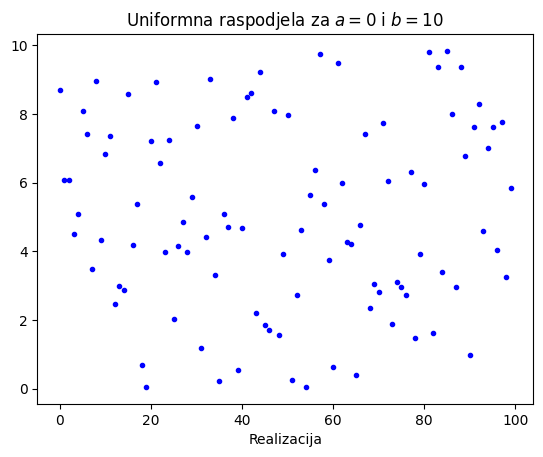

In [2]:
# Generiranje slučajne promjenljive iz uniformne raspodjele

N = 100  # Broj generiranih realizacija
a = 0; b = 10  # Parametri raspodjele

# Vektor od N realizacija slučajne promjenljive:
n = np.arange(N)
X = np.random.uniform(a, b, N)

print("Nekoliko vrijednosti slučajne promjenjive X: ", end="")
for x in X[0:5]:
    print("{:.2f}".format(x), end=" ")

ssp.slprom1D.realizacije(n, X,
                      naslov = "Uniformna raspodjela za $a=0$ i $b=10$")

U nastavku su nacrtane realizacije slučajne promjenljive zajedno sa očekivanom vrijednošću, odstupanja
promjenljive od očekivane vrijednosti (centrirana promjenljiva), te kvadrati slučajne promjenljive
(izvorne i centrirane).

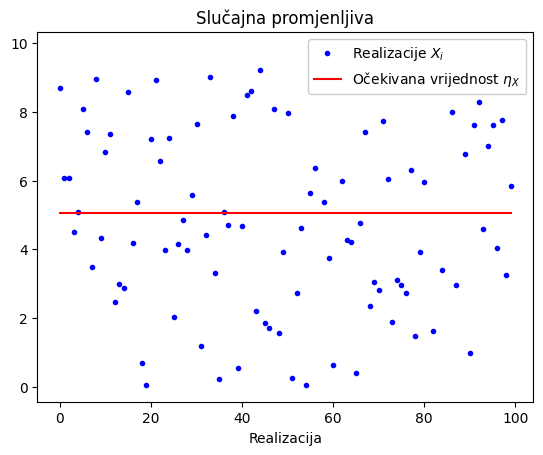

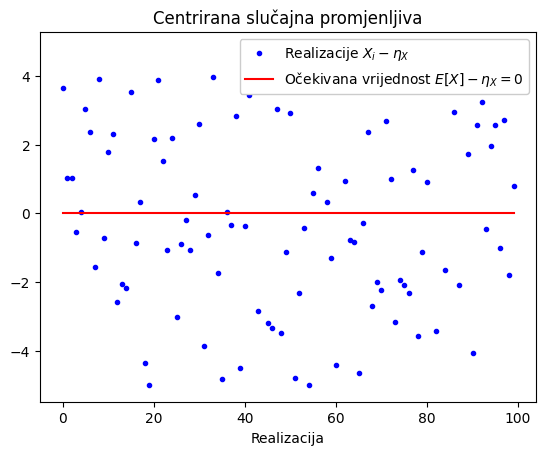

In [3]:
# Očekivana vrijednost slučajne promjenljive:
eta_X = np.mean(X)

#Vektor nad kojim se crta signal
n = np.arange(N)

ssp.slprom1D.realizacije(n, X, n, eta_X,
                      naslov = "Slučajna promjenljiva",
                      legenda = [r'Realizacije $X_i$',
                                 r'Očekivana vrijednost $\eta_X$']);

ssp.slprom1D.realizacije(n, X-eta_X, n, np.mean(X)-eta_X,
                      naslov = "Centrirana slučajna promjenljiva",
                      legenda = [r'Realizacije $X_i-\eta_X$',
                                 r'Očekivana vrijednost $E[X]-\eta_X=0$']);

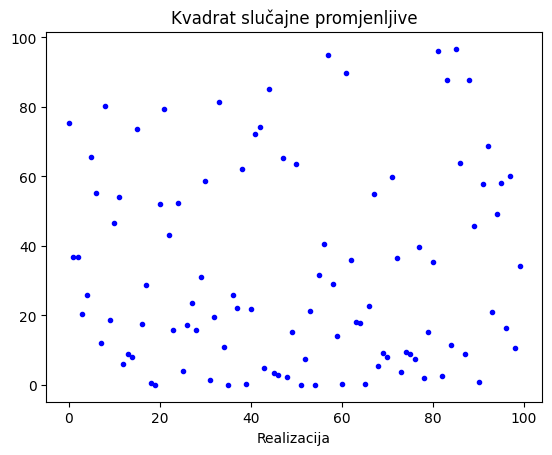

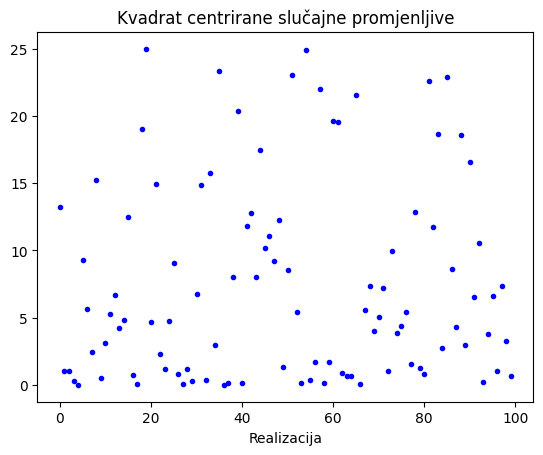

In [4]:
ssp.slprom1D.realizacije(n, X**2,
                        naslov = "Kvadrat slučajne promjenljive")

ssp.slprom1D.realizacije(n, (X - eta_X)**2,
                        naslov = "Kvadrat centrirane slučajne promjenljive")

## 2. Očekivana vrijednost
Za numeričke vrijednosti uzima se više realizacija, $N=2000$. Očekivana vrijednost se može izračunati kao srednja
vrijednost svih realizacija (ručno, petljom, ili gotovom funkcijom `np.mean`), ili analitički:
$E[X]=\frac{a+b}{2}$.

In [5]:
a = 0; b = 10; N = 2000; X = np.random.uniform(a, b, N)

suma = 0.0;
for i in range(0, N):
    suma = suma + X[i]

print("Očekivana vrijednost (numerički, 1. način): {:.2f}".format(suma/N))
print("Očekivana vrijednost (numerički, 2. način): {:.2f}".format(np.mean(X)))
print("Očekivana vrijednost (analitički): {:.2f}".format((a + b)/2))

Očekivana vrijednost (numerički, 1. način): 5.05
Očekivana vrijednost (numerički, 2. način): 5.05
Očekivana vrijednost (analitički): 5.00


Prva dva načina se ne razlikuju (to je isti račun), dok se analitički rezultat nešto razlikuje zbog konačnog broja realizacija $N$.

## 3. Srednjekvadratna vrijednost
Srednjekvadratna vrijednost je srednja vrijednost kvadrata realizacija, a analitički se dobiva kao
$E[X^2]=\frac{a^2+ab+b^2}{3}$.

In [6]:
print("Srednjekvadratna vrijednost (numerički): {:.2f}".format(np.mean(X*X)))
print("Srednjekvadratna vrijednost (analitički): {:.2f}".format((a**2 + a*b + b**2)/3))

Srednjekvadratna vrijednost (numerički): 34.17
Srednjekvadratna vrijednost (analitički): 33.33


## 4. Varijansa
Varijansa se može izračunati gotovom funkcijom `np.var`, po definiciji $E[(X-\eta_X)^2]$, preko veze
$\sigma_X^2=E[X^2]-\eta_X^2$, ili analitički: $\sigma_X^2=\frac{(b-a)^2}{12}$.

In [7]:
eta_X = np.mean(X)
sigma_X_2 = np.mean(X**2)

print("Varijansa (numerički, 1.način): {:.2f}".format(np.var(X)))
print("Varijansa (numerički, 2.način): {:.2f}".format(np.mean((X - eta_X)**2)))
print("Varijansa (numerički, 3.način): {:.2f}".format(sigma_X_2 - (eta_X**2)))
print("Varijansa (analitički): {:.2f}".format((b - a)**2/12))

Varijansa (numerički, 1.način): 8.63
Varijansa (numerički, 2.način): 8.63
Varijansa (numerički, 3.način): 8.63
Varijansa (analitički): 8.33


## 5. Medijana
Medijana $m$ je vrijednost za koju je vjerovatnoća($X\le m$) = vjerovatnoća($X\ge m$) $=\tfrac12$,
tj. $P_X(m)=\tfrac12$. Numerički se računa gotovom funkcijom `np.median`. Analitički, iz $P_X(m)=\tfrac12$
slijedi $\frac{m-a}{b-a}=\frac12\ \Rightarrow\ m=\frac{a+b}{2}$.

In [8]:
print("Medijana: {:.2f}".format(np.median(X)))
print("Medijana (analitički): {:.2f}".format((a + b)/2))

Medijana: 5.14
Medijana (analitički): 5.00


## 6. Funkcija raspodjele i funkcija gustine vjerovatnoće
Funkcija raspodjele vjerovatnoće se procjenjuje po definiciji: $P_X(x)$ je udio realizacija koje su $\le x$
(`ssp.slprom1D.PDF`). Funkcija gustine je njen izvod, $p_X(x)=\dfrac{dP_X(x)}{dx}$, koji se numerički
računa kao razlika susjednih vrijednosti podijeljena korakom (`ssp.slprom1D.pdf`).
Na kraju se eksperimentalne funkcije porede sa teoretskim:

$$P_X(x)=\frac{x-a}{b-a}\ \ (a\le x\le b),\qquad p_X(x)=\frac{1}{b-a}\ \ (a\le x\le b)$$

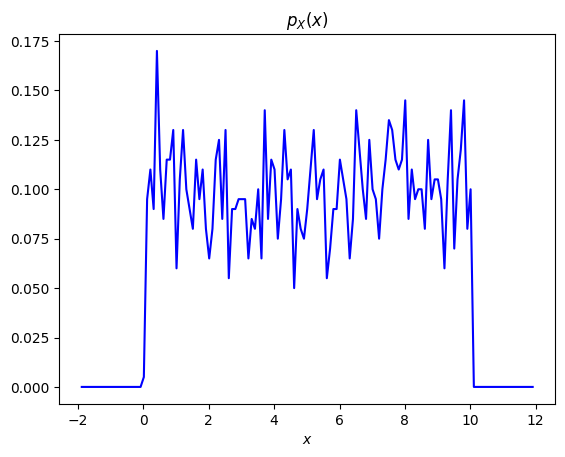

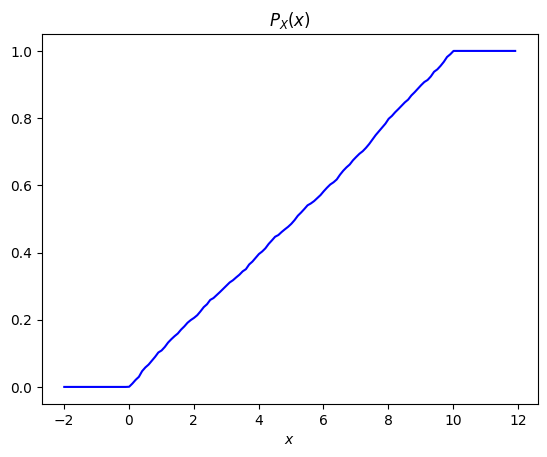

In [9]:
x, px = ssp.slprom1D.pdf(X)

x, Px = ssp.slprom1D.PDF(X)

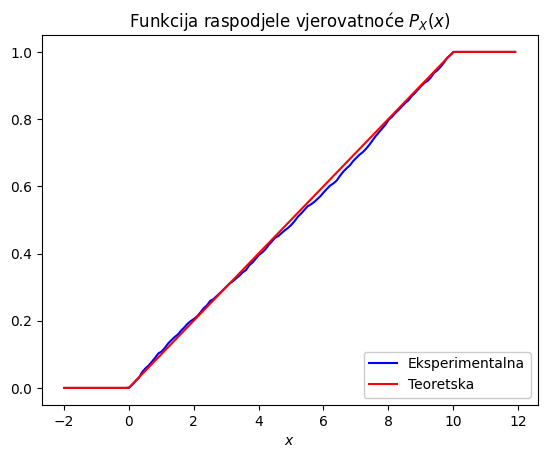

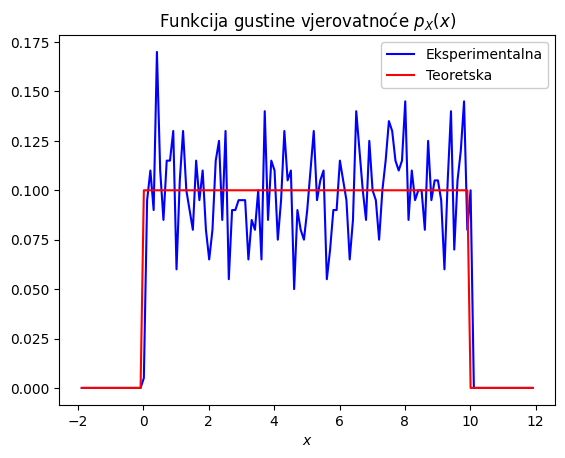

In [10]:
# Teoretske funkcije uniformne raspodjele
def P_teor(x):
    return np.clip((x - a)/(b - a), 0, 1)

def p_teor(x):
    return np.where((x >= a) & (x <= b), 1/(b - a), 0)

x, Px = ssp.slprom1D.PDF(X, prikaz = False)
ssp.slprom1D.grafik(x, Px, x, P_teor(x),
                 naslov = "Funkcija raspodjele vjerovatnoće $P_X(x)$",
                 legenda = ['Eksperimentalna', 'Teoretska'],
                 lokacija_lgd = 'lower right',
                 x_labela = "$x$")

x, px = ssp.slprom1D.pdf(X, prikaz = False)
ssp.slprom1D.grafik(x, px, x, p_teor(x),
                 naslov = "Funkcija gustine vjerovatnoće $p_X(x)$",
                 legenda = ['Eksperimentalna', 'Teoretska'],
                 x_labela = "$x$")

## 7. Sažetak

In [11]:
print("{:<28s}{:>12s}{:>12s}".format("", "numerički", "analitički"))
print("{:<28s}{:>12.4f}{:>12.4f}".format("Očekivana vrijednost", np.mean(X), (a + b)/2))
print("{:<28s}{:>12.4f}{:>12.4f}".format("Srednjekvadratna vrijednost", np.mean(X**2), (a**2 + a*b + b**2)/3))
print("{:<28s}{:>12.4f}{:>12.4f}".format("Varijansa", np.var(X), (b - a)**2/12))
print("{:<28s}{:>12.4f}{:>12.4f}".format("Medijana", np.median(X), (a + b)/2))

                               numerički  analitički
Očekivana vrijednost              5.0538      5.0000
Srednjekvadratna vrijednost      34.1709     33.3333
Varijansa                         8.6298      8.3333
Medijana                          5.1402      5.0000


**Zaključak.** Kod uniformne raspodjele realizacije su ravnomjerno „razbacane“ po cijelom intervalu $[0,10]$, bez ikakvog
zgušnjavanja. Funkcija raspodjele je prava linija od $0$ do $1$, a funkcija gustine je konstantna, $1/(b-a)=0{,}1$.
Raspodjela je simetrična, pa su očekivana vrijednost i medijana jednake, obje su u sredini intervala ($5$).